<!-- repro-header -->
> **Reproducibility header**
>
> - **Aim:** Per-gene uRNA metrics pooled across datasets and segmentations.
> - **Manuscript panels:** Fig. 3D, Fig. 3G (left), ED Fig. 5 (per-gene displacement)
> - **Inputs:** `xrna_metadata` table of every `data_with_source_score.zarr`
> - **Outputs:** `*_extracellular_proportion_strip.pdf`, `*_in_out_spearmanR_strip.pdf`, `*_logfoldchange_vs_extracellular_scatter.pdf`, example gene maps
> - **Environment / kernel:** `troutpy_drvi`
> - Data root: `/lustre/groups/ml01/datasets/projects/2025_sergio_troutpy` (ROIs on Zenodo 10.5281/zenodo.17446348). 


# Aim of the notebook
Revision of `5_overall_per_noise_gene_scatters.ipynb` for the current multi-segmentation ROI
dataset collection. For each segmentation method (`rois` = default, `rois_proseg`, `rois_segger`)
we combine the per-gene `xrna_metadata` table across all samples and produce one plot of each
type used in the original notebook:

1. `in_out_spearmanR` distribution per dataset
2. `extracellular_proportion` per dataset, colored by `logfoldchange_over_noise`
3. Per-gene noise scatter: `logfoldchange_over_noise` vs `extracellular_proportion`, colored by dataset
4. `mean_displacement` per dataset, split by diffusion significance (`ks_pval < 0.05`)

Paths and the segmentation/exclusion setup follow `1_summary_metrics_roi_analysis_revisions.ipynb`.

# Load modules

In [1]:
import os
import sys
import numpy as np
import pandas as pd
import anndata as ad
import matplotlib.pyplot as plt
import matplotlib
import seaborn as sns
import troutpy


# Set font type for vector output
matplotlib.rcParams['pdf.fonttype'] = 42
matplotlib.rcParams['ps.fonttype'] = 42


/home/icb/sergio.salas/miniconda3/envs/troutpy_drvi/lib/python3.10/site-packages/dask/dataframe/__init__.py:31: FutureWarning: The legacy Dask DataFrame implementation is deprecated and will be removed in a future version. Set the configuration option `dataframe.query-planning` to `True` or None to enable the new Dask Dataframe implementation and silence this warning.
  warnings.warn(


/home/icb/sergio.salas/miniconda3/envs/troutpy_drvi/lib/python3.10/site-packages/xarray_schema/__init__.py:1: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  from pkg_resources import DistributionNotFound, get_distribution


/home/icb/sergio.salas/miniconda3/envs/troutpy_drvi/lib/python3.10/site-packages/anndata/utils.py:434: FutureWarning: Importing read_text from `anndata` is deprecated. Import anndata.io.read_text instead.
  warnings.warn(msg, FutureWarning)


# Paths and dataset setup

In [2]:
# Base directory containing the different segmentation folders
base_dir = "/lustre/groups/ml01/datasets/projects/2025_sergio_troutpy/rois/"
saving_path = os.path.join(base_dir, "figures", "per_noise_gene_scatters")
os.makedirs(saving_path, exist_ok=True)

# Define the segmentations you want to process
segmentations = ["rois", "rois_proseg", "rois_segger"]
seg_name_map = {"rois": "def", "rois_proseg": "proseg", "rois_segger": "segger"}

# Samples to exclude from all downstream plots
excluded_samples = {"xenium_rcc", "cosmx_pancreas"}

# Per-gene metadata table with the columns used below (count, logfoldchange_over_noise,
# extracellular_proportion, in_out_spearmanR, ks_pval, mean_displacement, ...) is only
# available consistently across all three segmentation methods in this zarr store.
zarr_name = "data_with_source_score.zarr"


# Reading gene-level metadata
Combine the `xrna_metadata` table across all samples of a segmentation method. The table is
read directly from the zarr store (`tables/xrna_metadata`) instead of loading the full
`SpatialData` object, which is much faster since we only need the per-gene `.var` frame.

In [3]:
def load_combined_gene_metadata(seg, zarr_name=zarr_name):
    root_dir = os.path.join(base_dir, seg)
    records = []

    for subfolder in sorted(f.path for f in os.scandir(root_dir) if f.is_dir()):
        sample = os.path.basename(subfolder)
        if sample in excluded_samples:
            continue

        table_path = os.path.join(subfolder, zarr_name, "tables", "xrna_metadata")
        if not os.path.isdir(table_path):
            continue

        try:
            adata = ad.io.read_zarr(table_path)
            df = adata.var.copy()
            df["Gene"] = df.index
            df["dataset"] = sample
            records.append(df)
        except Exception as e:
            print(f"Failed to read {table_path}: {e}")

    if records:
        combined = pd.concat(records, axis=0, ignore_index=True)
        print(f"[{seg}] combined gene-metadata shape: {combined.shape}")
        return combined

    print(f"[{seg}] no gene metadata loaded.")
    return pd.DataFrame()


combined_metadata_dict = {seg: load_combined_gene_metadata(seg) for seg in segmentations}


[rois] combined gene-metadata shape: (71680, 27)


[rois_proseg] combined gene-metadata shape: (71680, 27)


[rois_segger] combined gene-metadata shape: (71680, 27)


In [4]:
# Fixed dataset -> color mapping shared across all segmentations/plots below, so the same
# dataset always gets the same color even when a panel's sample coverage differs.
dataset_order_all = sorted(set().union(*(
    set(df["dataset"].unique()) for df in combined_metadata_dict.values() if not df.empty
)))
dataset_palette = dict(zip(dataset_order_all, troutpy.pl.get_palette("30colors")))


## Plot 1: `in_out_spearmanR` per dataset

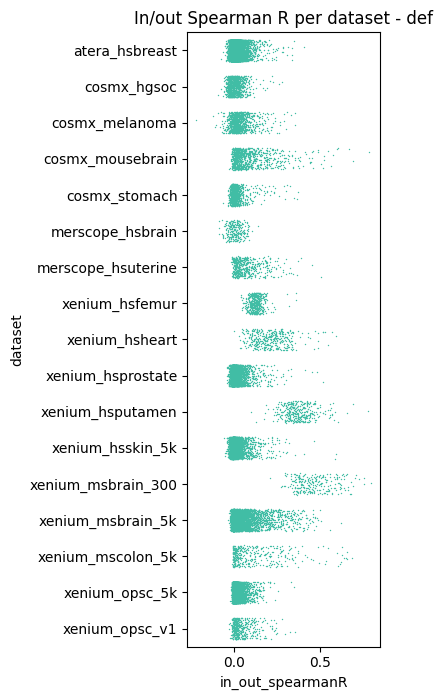

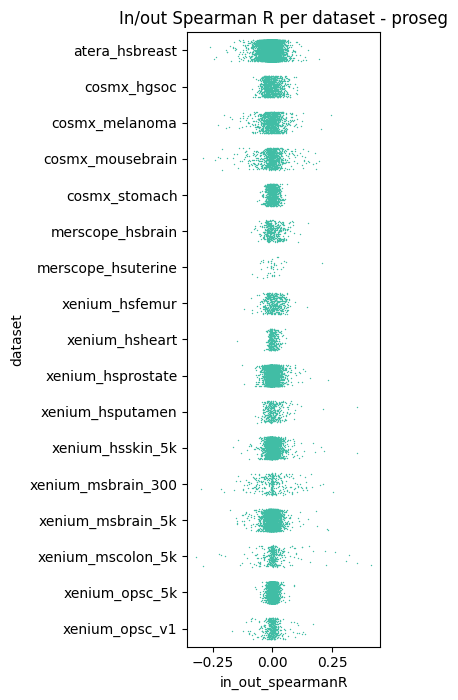

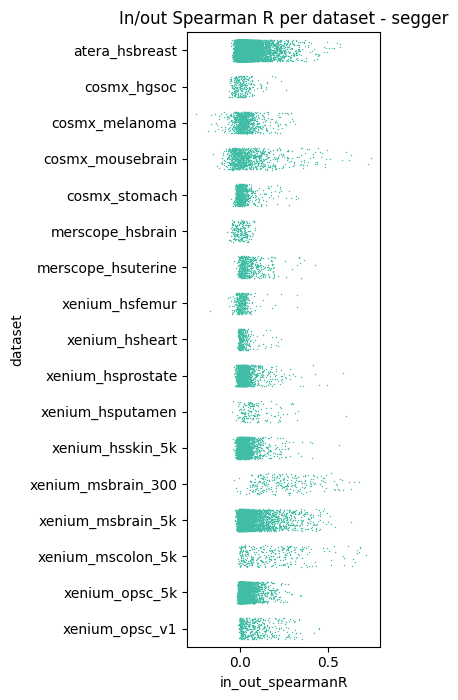

In [5]:
for seg, df in combined_metadata_dict.items():
    if df.empty:
        continue
    seg_label = seg_name_map.get(seg, seg)
    dataset_order = sorted(df["dataset"].unique())

    plt.figure(figsize=(4, 0.3 * len(dataset_order) + 2))
    sns.stripplot(
        data=df, y="dataset", x="in_out_spearmanR",
        order=dataset_order, s=1, color="#41bda5", jitter=0.3,
    )
    plt.title(f"In/out Spearman R per dataset - {seg_label}")
    plt.tight_layout()
    plt.savefig(os.path.join(saving_path, f"{seg_label}_in_out_spearmanR_strip.pdf"), bbox_inches="tight")
    plt.show()


## Plot 2: `extracellular_proportion` per dataset, colored by `logfoldchange_over_noise`

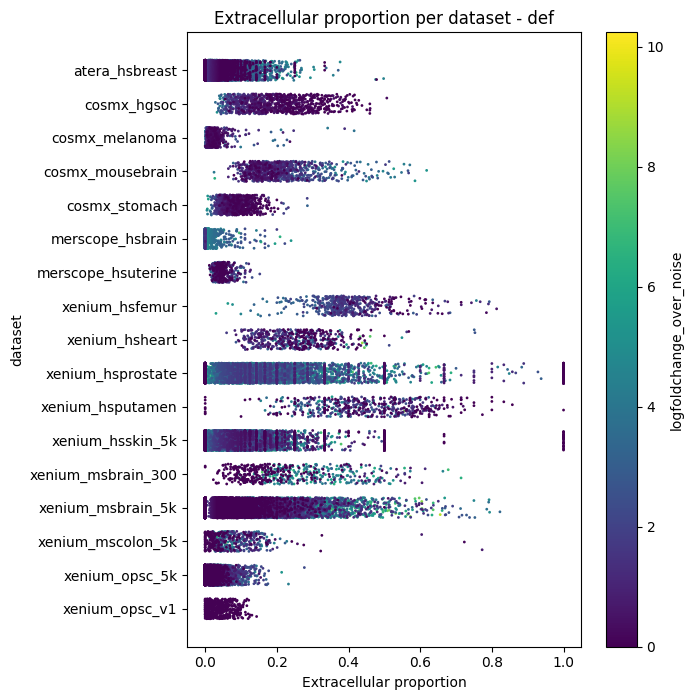

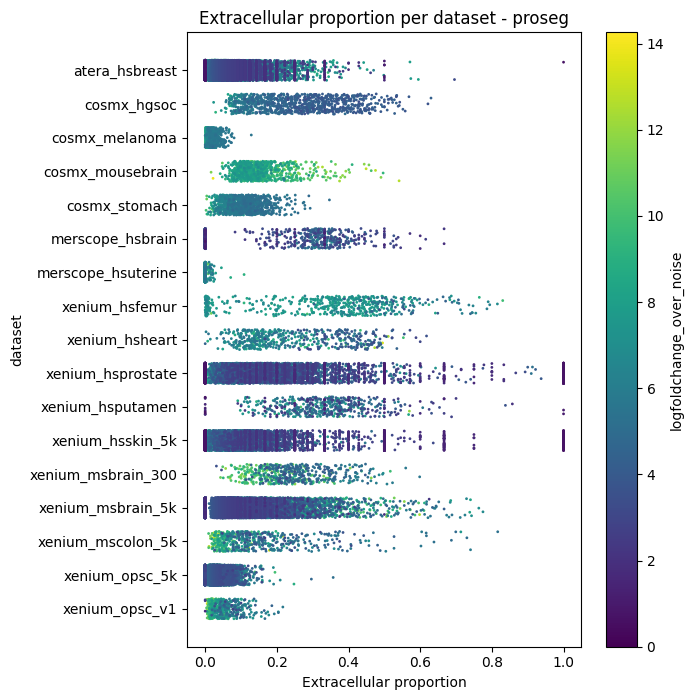

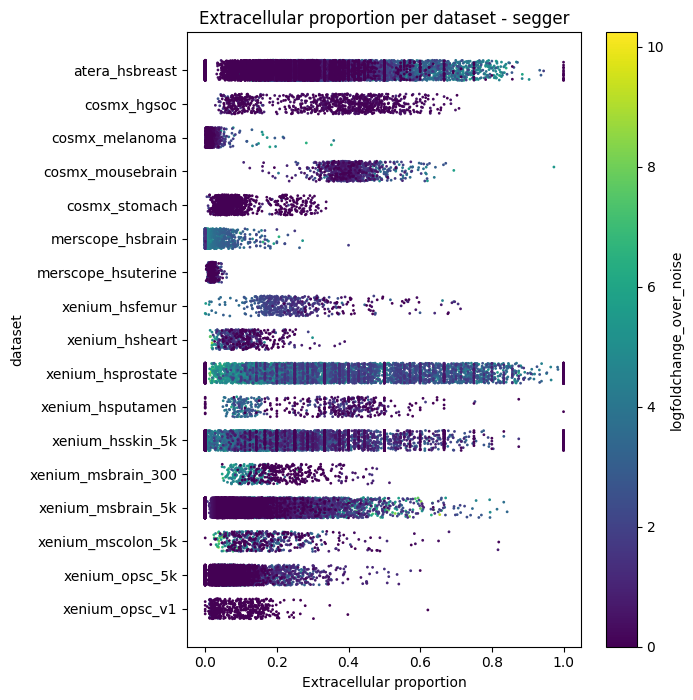

In [6]:
for seg, df in combined_metadata_dict.items():
    if df.empty:
        continue
    seg_label = seg_name_map.get(seg, seg)
    dataset_order = sorted(df["dataset"].unique())
    y_pos = {d: i for i, d in enumerate(dataset_order)}

    rng = np.random.default_rng(0)
    y_jittered = df["dataset"].map(y_pos) + rng.uniform(-0.3, 0.3, size=len(df))

    # Continuous colorbar clamped at 0: negative logfoldchange_over_noise values (below the
    # noise threshold) all saturate to the same color as 0, instead of stretching the
    # colormap down to the (uninformative) most-negative value.
    norm = matplotlib.colors.Normalize(vmin=0, vmax=df["logfoldchange_over_noise"].max())

    fig, ax = plt.subplots(figsize=(7, 0.3 * len(dataset_order) + 2))
    sc = ax.scatter(
        df["extracellular_proportion"], y_jittered,
        c=df["logfoldchange_over_noise"], cmap="viridis", norm=norm,
        s=4, linewidths=0, rasterized=True,
    )
    ax.set_yticks(range(len(dataset_order)))
    ax.set_yticklabels(dataset_order)
    ax.invert_yaxis()
    ax.set_xlabel("Extracellular proportion")
    ax.set_ylabel("dataset")
    ax.set_title(f"Extracellular proportion per dataset - {seg_label}")
    cbar = fig.colorbar(sc, ax=ax)
    cbar.set_label("logfoldchange_over_noise")
    plt.tight_layout()
    plt.savefig(os.path.join(saving_path, f"{seg_label}_extracellular_proportion_strip.pdf"), dpi=200, bbox_inches="tight")
    plt.show()


## Plot 3: per-gene noise scatter
`logfoldchange_over_noise` vs `extracellular_proportion`, combined across all samples of a
segmentation method and colored by dataset.

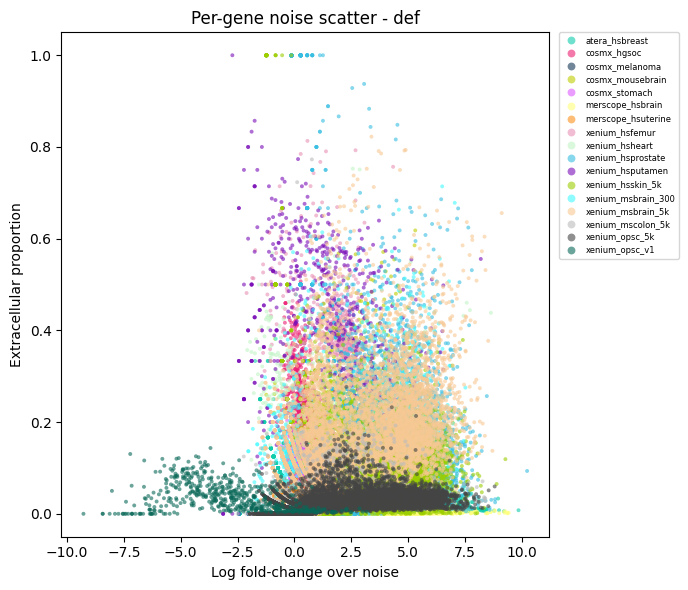

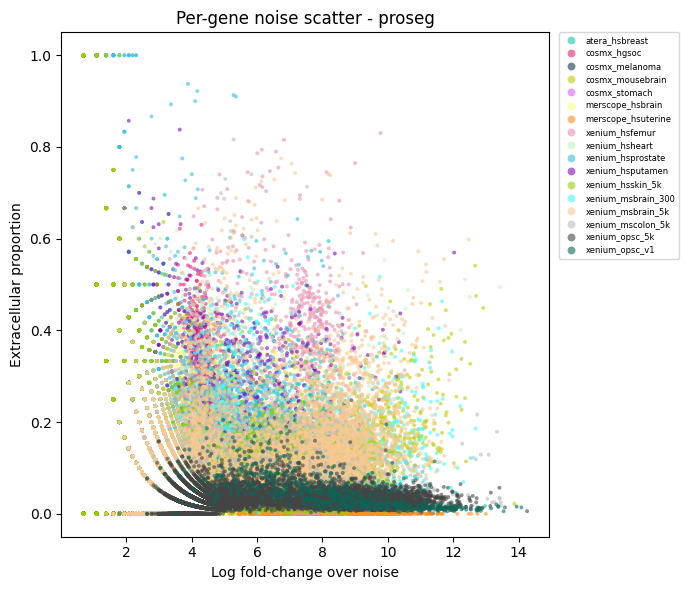

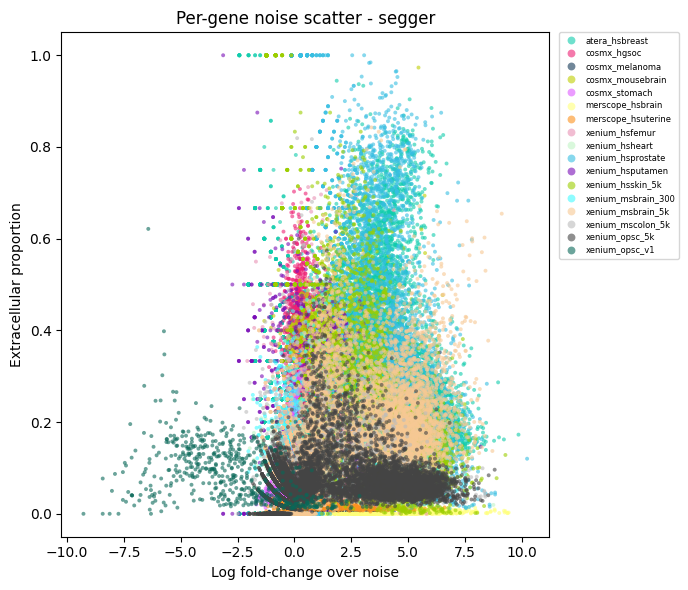

In [7]:
for seg, df in combined_metadata_dict.items():
    if df.empty:
        continue
    seg_label = seg_name_map.get(seg, seg)
    plot_df = df.dropna(subset=["logfoldchange_over_noise", "extracellular_proportion"])
    present_datasets = [d for d in dataset_order_all if d in plot_df["dataset"].unique()]

    plt.figure(figsize=(7, 6))
    sns.scatterplot(
        data=plot_df, x="logfoldchange_over_noise", y="extracellular_proportion",
        hue="dataset", hue_order=present_datasets, palette=dataset_palette,
        s=8, alpha=0.6, linewidth=0,
    )
    plt.xlabel("Log fold-change over noise")
    plt.ylabel("Extracellular proportion")
    plt.title(f"Per-gene noise scatter - {seg_label}")
    plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left", borderaxespad=0, markerscale=2, fontsize=6)
    plt.tight_layout()
    plt.savefig(
        os.path.join(saving_path, f"{seg_label}_logfoldchange_vs_extracellular_scatter.pdf"),
        bbox_inches="tight",
    )
    plt.show()


## Plot 4: `mean_displacement` per dataset, split by diffusion significance (`ks_pval < 0.05`)

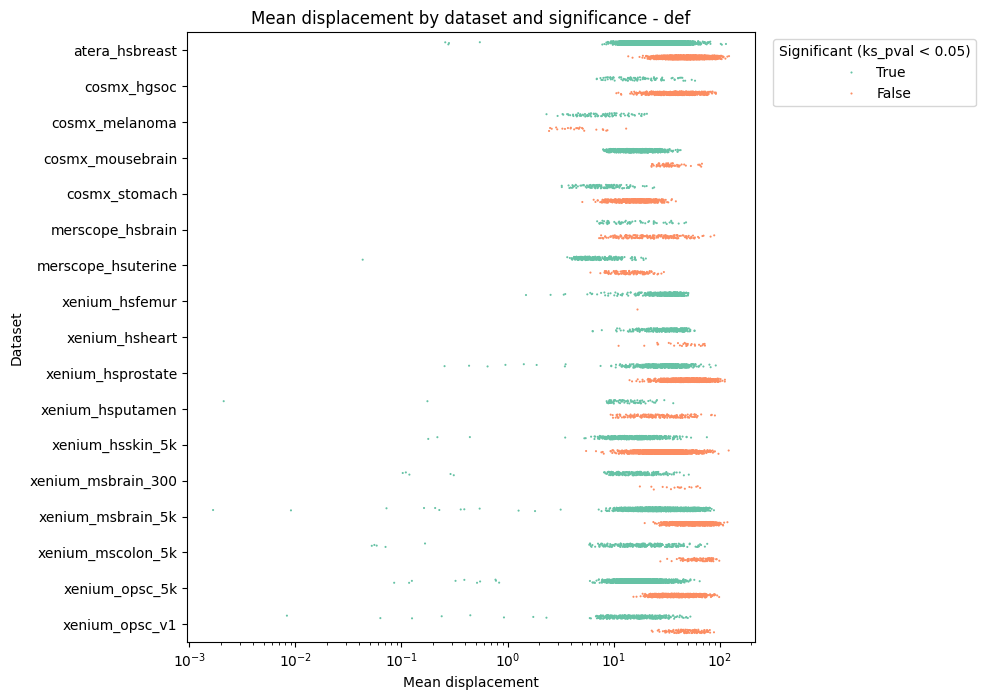

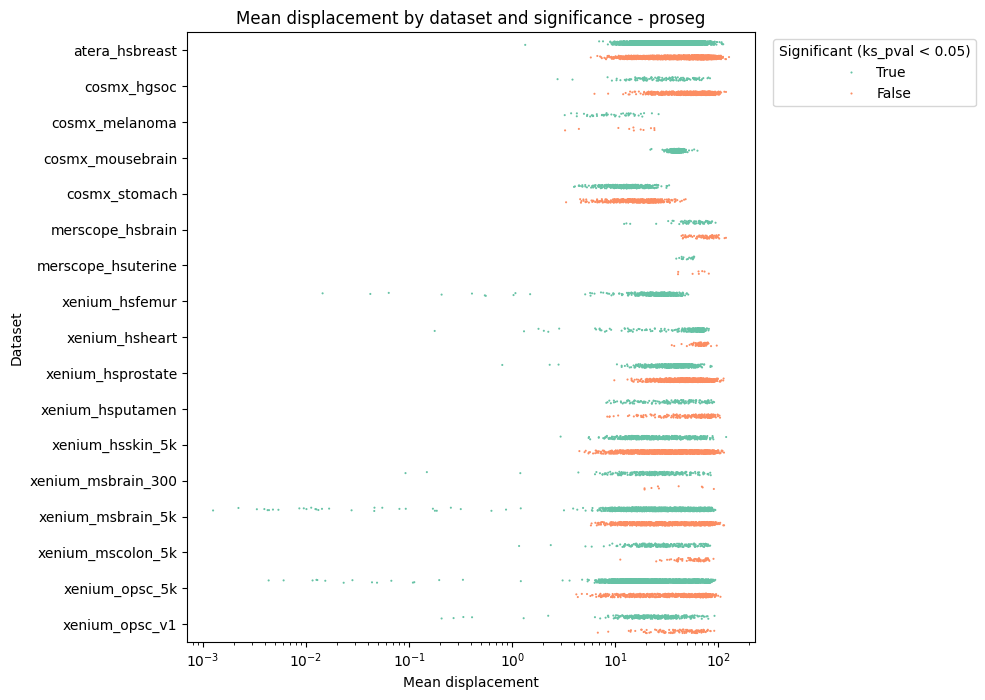

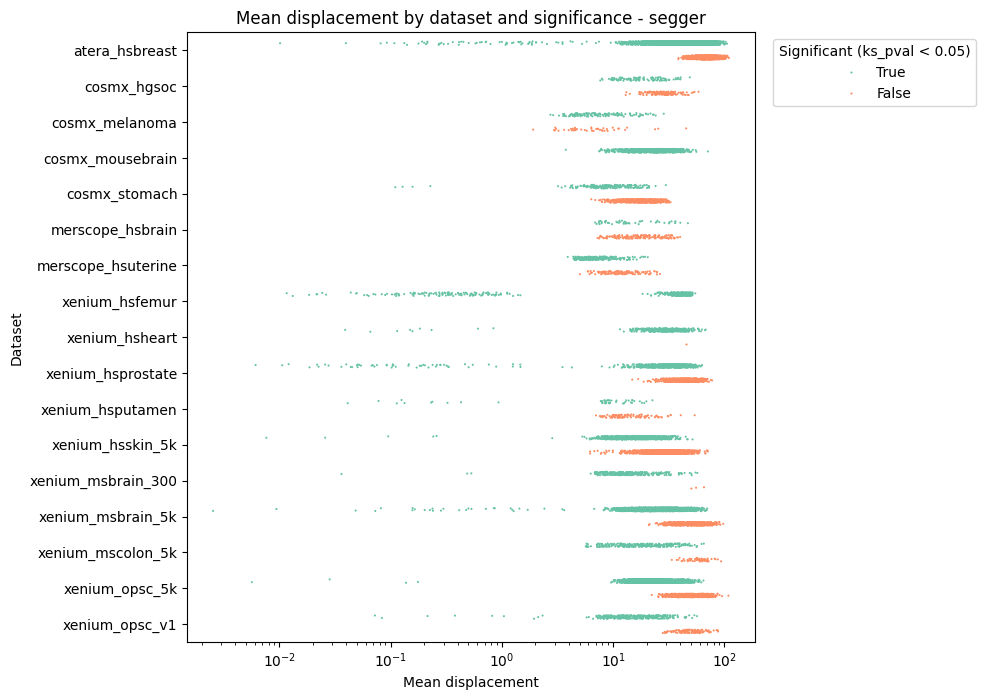

In [8]:
for seg, df in combined_metadata_dict.items():
    if df.empty:
        continue
    seg_label = seg_name_map.get(seg, seg)
    plot_df = df.dropna(subset=["ks_pval", "mean_displacement"]).copy()
    plot_df["significant"] = plot_df["ks_pval"] < 0.05
    dataset_order = sorted(plot_df["dataset"].unique())

    plt.figure(figsize=(10, 0.3 * len(dataset_order) + 2))
    sns.stripplot(
        data=plot_df, y="dataset", x="mean_displacement",
        order=dataset_order, hue="significant", hue_order=[True, False],
        dodge=True, jitter=True, palette="Set2", s=1.5,
    )
    plt.xscale("log")
    plt.xlabel("Mean displacement")
    plt.ylabel("Dataset")
    plt.title(f"Mean displacement by dataset and significance - {seg_label}")
    plt.legend(title="Significant (ks_pval < 0.05)", bbox_to_anchor=(1.02, 1), loc="upper left")
    plt.tight_layout()
    plt.savefig(
        os.path.join(saving_path, f"{seg_label}_mean_displacement_by_significance_strip.pdf"),
        bbox_inches="tight",
    )
    plt.show()


## Plot 5: spatial spotlight on low-correlation, high-uRNA-proportion genes
A very low `in_out_spearmanR` (no coherent relationship between intracellular and
extracellular counts across cells) is not just statistical noise - it is exactly what we'd
expect from a gene whose signal is predominantly extracellular (a high uRNA / extracellular
proportion), since there is then little intracellular signal left for the extracellular
signal to track. To illustrate this, we look **only** for that specific pattern: genes with
a very low `in_out_spearmanR` *and* a high `extracellular_proportion` (uRNA proportion),
restricted to well-expressed genes (`count >= 1000`) so the examples are not driven by
small-sample noise. We rank genes (within the default `rois` segmentation) by
`percentile(extracellular_proportion) - percentile(in_out_spearmanR)` and take the top
candidate gene from each of the highest-scoring datasets, then plot each one spatially with
`spatial_transcripts`, colored by transcript source category.

Two data quirks are handled explicitly below (see the reproducibility repo notes on
uRNA/morphology pitfalls for related gotchas):
- `control_probe` is inverted from what its name suggests: `True` marks a normal gene,
  `False` marks a technical negative-control probe (e.g. `NegPrbN`) - those must be excluded,
  not kept.
- For at least one MERSCOPE ROI (`merscope_hsbrain`), the recorded coordinate transform for
  the cell-boundary shapes does not align with the transcripts' coordinate frame (a data bug,
  not a code bug) - applying it as-is throws the boundaries far outside the tissue. We check
  bounding-box overlap against the transcripts and fall back to the untransformed (correctly
  aligned) geometry when the recorded transform makes things worse.

`troutpy.pl.spatial_transcripts` is not yet in the released troutpy version installed in this
kernel, so the function (from the in-development troutpy source) is embedded below.

In [9]:
import geopandas as gpd
from matplotlib.colors import ListedColormap, Normalize
from shapely.affinity import affine_transform
from shapely.geometry import box
import spatialdata as sd
from spatialdata import SpatialData
from spatialdata.transformations import get_transformation, set_transformation, Identity
from troutpy.pl.colors import get_colormap, get_palette


def spatial_transcripts(
    sdata: SpatialData,
    gene_key: str = "gene",
    gene_list: list[str] | None = None,
    color_key: str = "point_source_cellular",
    shapes_key: str = "cell_boundaries",
    table_key: str = "table",
    structure_table_key: str = "structure_table",
    source_table_key: str = "source_score",
    colormap: str = "30colors",
    continuous_colormap: str = "viridis",
    boundary_linewidth: float = 0.5,
    boundary_zorder: int = 4,
    scatter_size: float = 1.0,
    alpha: float = 0.8,
    use_roi: bool = False,
    roi: tuple[float, float, float, float] = (0, 20000, 0, 20000),
    figsize: tuple[float, float] = (8, 8),
    title: str = "Cell Boundaries + Transcripts",
    vmin: float | None = None,
    vmax: float | None = None,
    rasterize: bool = True,
    missing_val_sentinel: int | str | float = -1,
) -> tuple[plt.Figure, plt.Axes]:
    """Plot spatial transcripts colored by a grouping variable, overlaid on cell boundaries.

    For ``color_key="point_source_cellular"`` (the default), transcripts are colored by
    whether they overlap a cell (``"cellular transcripts"``) or, for extracellular
    transcripts, by their predicted source category from ``sdata[source_table_key]``.
    """
    target_col = "point_source" if color_key == "point_source_cellular" else color_key
    required_cols = ["x", "y", gene_key, "overlaps_cell"]

    transcripts_lazy = sdata.points["transcripts"]
    is_direct_column = target_col in transcripts_lazy.columns

    if is_direct_column:
        required_cols.append(target_col)

    search_configs = [
        (source_table_key, None),
        (structure_table_key, "structure_id"),
        (table_key, "cell_id"),
    ]

    for t_key, trans_id_col in search_configs:
        if t_key in sdata.tables and target_col in sdata[t_key].obs.columns:
            if trans_id_col is not None:
                required_cols.append(trans_id_col)
            break

    required_cols = list(set(required_cols))
    available_cols = [c for c in required_cols if c in transcripts_lazy.columns]
    transcripts_lazy_subset = transcripts_lazy[available_cols]

    if gene_list is not None:
        transcripts_lazy_subset = transcripts_lazy_subset[transcripts_lazy_subset[gene_key].isin(gene_list)]

    trans_ad = transcripts_lazy_subset.compute().copy()

    if color_key not in trans_ad.columns:
        trans_ad[color_key] = np.nan

    if color_key == "point_source_cellular":
        if target_col not in trans_ad.columns:
            trans_ad[target_col] = np.nan

            for t_key, trans_id_col in search_configs:
                if t_key in sdata.tables and target_col in sdata[t_key].obs.columns:
                    table_obs = sdata[t_key].obs
                    if trans_id_col is None:
                        table_series = table_obs[target_col]
                        table_series.index = table_series.index.astype(str)
                        trans_ad[target_col] = trans_ad.index.astype(str).map(table_series)
                    else:
                        if "instance_id" in table_obs.columns:
                            map_source = table_obs.set_index("instance_id")[target_col]
                        elif "cell_id" in table_obs.columns:
                            map_source = table_obs.set_index("cell_id")[target_col]
                        else:
                            map_source = table_obs[target_col]

                        map_source.index = map_source.index.astype(str)
                        trans_ad[target_col] = trans_ad[trans_id_col].astype(str).map(map_source)

                    if not trans_ad[target_col].isna().all():
                        break

        is_intra_bool = trans_ad["overlaps_cell"].astype(str).str.lower() == "true"
        trans_ad["point_source_cellular"] = np.where(is_intra_bool, "cellular transcripts", trans_ad[target_col].astype(str))
        trans_ad.loc[trans_ad[target_col].isna(), "point_source_cellular"] = np.nan

    elif is_direct_column is False:
        for t_key, trans_id_col in search_configs:
            if t_key in sdata.tables and color_key in sdata[t_key].obs.columns:
                table_obs = sdata[t_key].obs
                if trans_id_col is None:
                    table_series = table_obs[color_key]
                    table_series.index = table_series.index.astype(str)
                    trans_ad[color_key] = trans_ad.index.astype(str).map(table_series)
                else:
                    if "instance_id" in table_obs.columns:
                        map_source = table_obs.set_index("instance_id")[color_key]
                    elif "cell_id" in table_obs.columns:
                        map_source = table_obs.set_index("cell_id")[color_key]
                    else:
                        map_source = table_obs[color_key]

                    map_source.index = map_source.index.astype(str)
                    trans_ad[color_key] = trans_ad[trans_id_col].astype(str).map(map_source)

                if not trans_ad[color_key].isna().all():
                    break

    trans_ad[color_key] = trans_ad[color_key].replace("nan", np.nan)
    if missing_val_sentinel is not None:
        sentinel_str = str(missing_val_sentinel)
        trans_ad[color_key] = trans_ad[color_key].replace([missing_val_sentinel, sentinel_str], np.nan)

    is_nan_mask = trans_ad[color_key].isna()
    trans_ad[color_key] = trans_ad[color_key].fillna("Unmapped")
    is_bg = trans_ad[color_key] == "Unmapped"
    trans_df = trans_ad.copy()

    # Cell boundary geometries, transformed into the same coordinate space as the transcripts
    cb = sdata[shapes_key]
    df = cb.copy()
    try:
        trans = get_transformation(cb)
        if hasattr(trans, "matrix") and trans.matrix is not None:
            m = trans.matrix
            params = [m[0, 0], m[0, 1], m[1, 0], m[1, 1], m[0, 2], m[1, 2]]
            df["geometry"] = df["geometry"].apply(lambda g: affine_transform(g, params))
    except Exception:  # noqa: BLE001 - best-effort: plot untransformed shapes if transform lookup/application fails
        pass
    gdf = gpd.GeoDataFrame(df, geometry="geometry")

    if use_roi:
        xmin, xmax, ymin, ymax = roi
        roi_poly = box(xmin, ymin, xmax, ymax)
        gdf = gdf[gdf.geometry.intersects(roi_poly)]
        mask = (trans_df["x"] >= xmin) & (trans_df["x"] <= xmax) & (trans_df["y"] >= ymin) & (trans_df["y"] <= ymax)
        trans_df = trans_df[mask]
        is_bg = is_bg[mask]
        is_nan_mask = is_nan_mask[mask]

    fg_df = trans_df[~is_bg].copy()
    unmapped_df = trans_df[is_bg & ~is_nan_mask].copy()

    cmap, norm, is_numeric, cats = None, None, False, None

    if not fg_df.empty:
        numeric_check = pd.to_numeric(fg_df[color_key], errors="coerce")
        if not numeric_check.isna().all() and pd.api.types.is_numeric_dtype(numeric_check):
            is_numeric = True
            vals = fg_df[color_key].astype(float)

            try:
                cmap = plt.get_cmap(colormap)
            except ValueError:
                cmap = plt.get_cmap(continuous_colormap)

            plot_vmin = vmin if vmin is not None else vals.min()
            plot_vmax = vmax if vmax is not None else (1.0 if vals.max() <= 1.0 else vals.max())
            norm = Normalize(vmin=plot_vmin, vmax=plot_vmax)
        else:
            is_numeric = False

            if color_key == "point_source_cellular":
                defined_order = ["cellular transcripts", "cell_like_source", "other", "high_density_source"]
                present_cats = [c for c in defined_order if c in fg_df[color_key].unique()]
                extra_cats = [c for c in fg_df[color_key].unique() if c not in defined_order]
                final_order = present_cats + extra_cats
                fg_df[color_key] = pd.Categorical(fg_df[color_key], categories=final_order, ordered=True)
            else:
                fg_df[color_key] = fg_df[color_key].astype("category")

            cats = fg_df[color_key].cat.categories

            if isinstance(colormap, ListedColormap):
                cmap = colormap
            else:
                try:
                    pal = get_palette(colormap, len(cats))
                    cmap = ListedColormap(pal)
                except ValueError:
                    cmap = plt.get_cmap(colormap if colormap in plt.colormaps() else "tab20", len(cats))

    fig, ax = plt.subplots(figsize=figsize)

    gdf.plot(ax=ax, facecolor="none", edgecolor="black", linewidth=boundary_linewidth, alpha=0.4, zorder=boundary_zorder)

    if not unmapped_df.empty:
        ax.scatter(unmapped_df["x"], unmapped_df["y"], c="#A0A0A0", s=scatter_size, edgecolor="none", alpha=alpha, zorder=2, rasterized=rasterize)

    if not fg_df.empty:
        c_vals = fg_df[color_key] if is_numeric else fg_df[color_key].cat.codes
        scatter = ax.scatter(
            fg_df["x"],
            fg_df["y"],
            c=c_vals,
            cmap=cmap,
            norm=norm if is_numeric else None,
            s=scatter_size * 1.5,
            edgecolor="none",
            alpha=1.0,
            zorder=3,
            rasterized=rasterize,
        )
        if is_numeric:
            fig.colorbar(scatter, ax=ax, label=color_key, fraction=0.046, pad=0.04)
        else:
            if len(cats) <= 30:
                for idx, cat in enumerate(cats):
                    ax.scatter([], [], color=cmap(idx), label=str(cat), s=20)
                ax.legend(title=color_key, markerscale=1.5, bbox_to_anchor=(1.02, 1), loc="upper left")

    ax.set_aspect("equal")
    ax.set_title(title)
    if use_roi:
        ax.set_xlim(roi[0], roi[1])
        ax.set_ylim(roi[2], roi[3])
    ax.axis("off")
    plt.tight_layout()

    return fig, ax


In [10]:
# Identify genes with a very low in_out_spearmanR (no coherent relationship between
# intra/extracellular counts) that is specifically paired with a high extracellular_proportion
# (uRNA proportion) - i.e. genes where the low correlation is exactly explained by the signal
# being predominantly extracellular. Restricted to the default segmentation.
noise_df = combined_metadata_dict["rois"].dropna(subset=["in_out_spearmanR", "extracellular_proportion"]).copy()

# control_probe is inverted from what its name suggests: True = normal gene, False = a
# technical negative-control probe (e.g. NegPrbN) - drop the negative-control probes.
noise_df = noise_df[noise_df["control_probe"].astype(bool)]
noise_df = noise_df[noise_df["count"] >= 1000]  # keep only well-expressed genes, not small-sample noise

noise_df["urna_pct"] = noise_df["extracellular_proportion"].rank(pct=True)
noise_df["spearman_pct"] = noise_df["in_out_spearmanR"].rank(pct=True)
noise_df["score"] = noise_df["urna_pct"] - noise_df["spearman_pct"]

# Take the single top-scoring gene per dataset, then the top N such datasets by that score
n_datasets = 4
top_per_dataset = noise_df.sort_values("score", ascending=False).groupby("dataset", sort=False).head(1)
spotlight_candidates = top_per_dataset.sort_values("score", ascending=False).head(n_datasets)

print(spotlight_candidates[["dataset", "Gene", "extracellular_proportion", "in_out_spearmanR", "score", "count"]].to_string(index=False))

          dataset  Gene  extracellular_proportion  in_out_spearmanR    score  count
xenium_hsprostate CGNL1                  0.333333         -0.040774 0.952196   1101
xenium_msbrain_5k Vipr1                  0.436496         -0.017783 0.951981   1929
 cosmx_mousebrain  Scd2                  0.353134         -0.025084 0.949025 103564
 xenium_hsskin_5k CALM3                  0.220132         -0.015197 0.839207   2871



=== xenium_hsprostate / CGNL1 (spearmanR=-0.041, uRNA proportion=0.33) ===


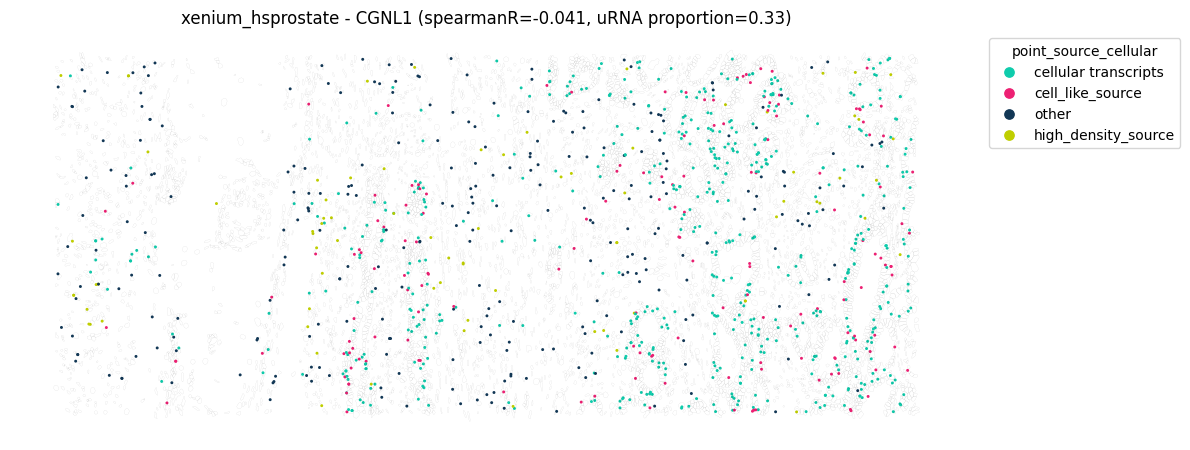


=== xenium_msbrain_5k / Vipr1 (spearmanR=-0.018, uRNA proportion=0.44) ===


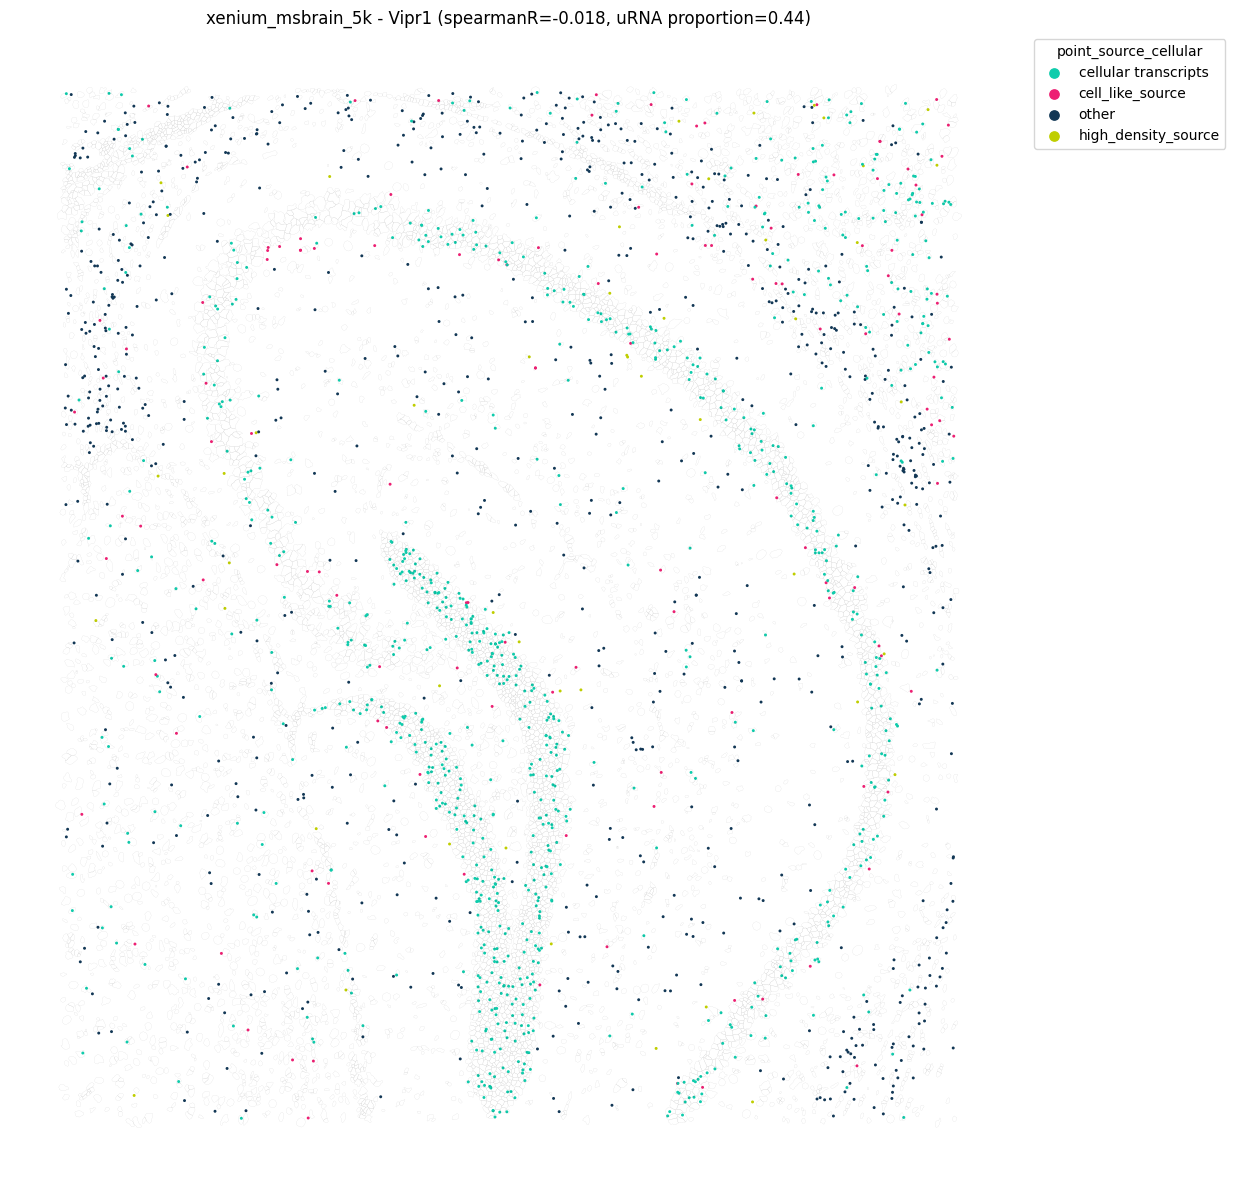


=== cosmx_mousebrain / Scd2 (spearmanR=-0.025, uRNA proportion=0.35) ===


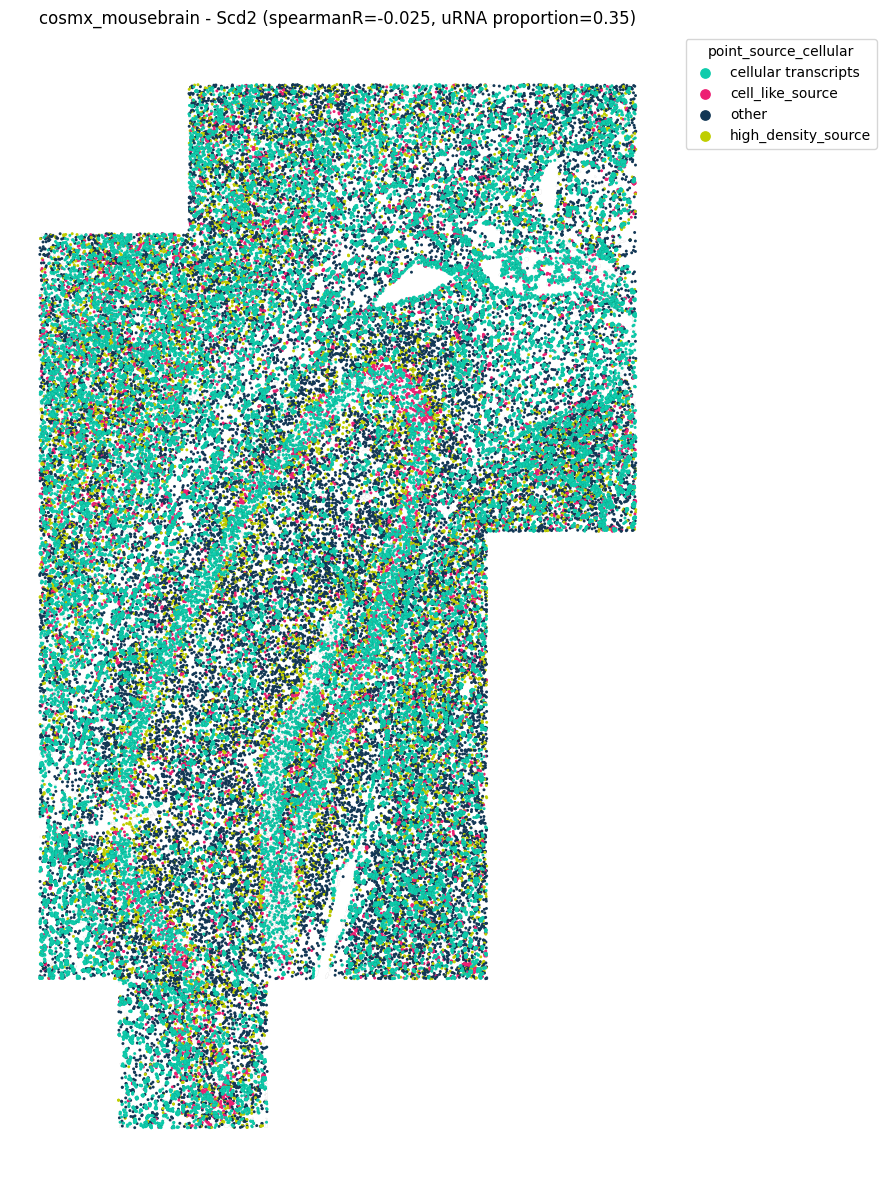


=== xenium_hsskin_5k / CALM3 (spearmanR=-0.015, uRNA proportion=0.22) ===


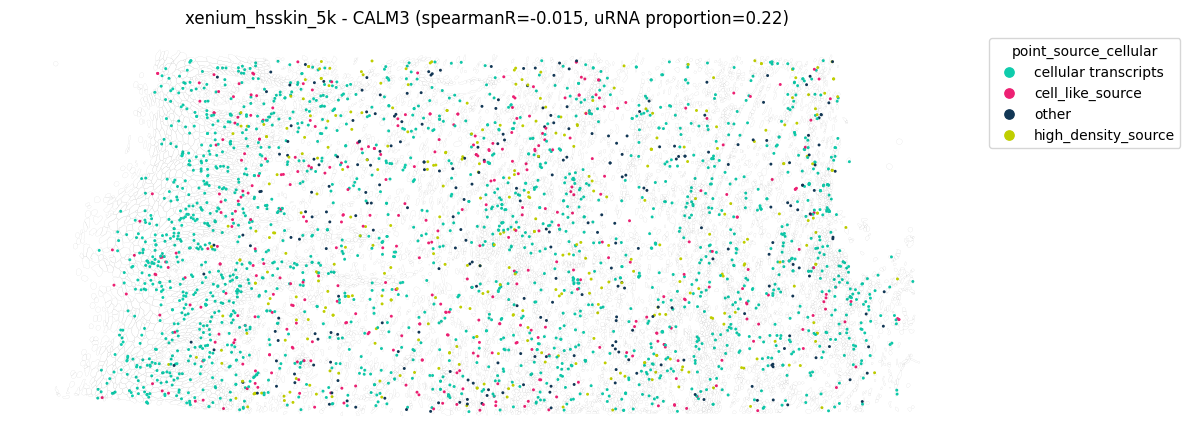

In [11]:
def bbox_iou(a, b):
    ax0, ay0, ax1, ay1 = a
    bx0, by0, bx1, by1 = b
    ix0, iy0 = max(ax0, bx0), max(ay0, by0)
    ix1, iy1 = min(ax1, bx1), min(ay1, by1)
    iw, ih = max(0, ix1 - ix0), max(0, iy1 - iy0)
    inter = iw * ih
    union = (ax1 - ax0) * (ay1 - ay0) + (bx1 - bx0) * (by1 - by0) - inter
    return inter / union if union > 0 else 0


def fix_misaligned_shapes_transform(sdata, shapes_key):
    """Some ROIs carry a recorded 'global' transform for their cell-boundary shapes that
    does not actually align with the transcripts' coordinate frame (seen for at least one
    MERSCOPE ROI, likely stale/incorrect metadata from an earlier processing step). Detect
    this via bounding-box overlap and fall back to the untransformed geometry when it helps.
    """
    trans_xy = sdata.points["transcripts"][["x", "y"]].compute()
    t_bounds = (trans_xy["x"].min(), trans_xy["y"].min(), trans_xy["x"].max(), trans_xy["y"].max())

    shp = sdata.shapes[shapes_key]
    raw_bounds = tuple(shp.total_bounds)

    tr = get_transformation(shp)
    if hasattr(tr, "matrix") and tr.matrix is not None:
        m = tr.matrix
        corners = np.array([[raw_bounds[0], raw_bounds[1], 1], [raw_bounds[2], raw_bounds[3], 1]])
        tc = corners @ m.T
        transformed_bounds = (tc[:, 0].min(), tc[:, 1].min(), tc[:, 0].max(), tc[:, 1].max())
    else:
        transformed_bounds = raw_bounds

    if bbox_iou(raw_bounds, t_bounds) > bbox_iou(transformed_bounds, t_bounds):
        print(f"  [fix] '{shapes_key}' transform misaligns with transcripts; resetting to Identity")
        set_transformation(shp, Identity(), to_coordinate_system="global")


base_dir_seg = os.path.join(base_dir, "rois")

for _, row in spotlight_candidates.iterrows():
    dataset, gene = row["dataset"], row["Gene"]
    print(f"\n=== {dataset} / {gene} (spearmanR={row['in_out_spearmanR']:.3f}, uRNA proportion={row['extracellular_proportion']:.2f}) ===")

    zarr_path = os.path.join(base_dir_seg, dataset, zarr_name)
    sdata = sd.read_zarr(zarr_path, selection=("points", "shapes", "tables"))

    shapes_key = "cell_boundaries" if "cell_boundaries" in sdata.shapes else "shapes"
    fix_misaligned_shapes_transform(sdata, shapes_key)

    # scatter_size=0.01 (as originally requested) is sized for an all-genes, whole-tissue
    # view with potentially millions of points; restricted to a single gene's transcripts
    # (a few thousand to ~30k points here), that size renders as effectively invisible even
    # in the vector PDF. Use a size that's actually visible for this point density instead.
    fig, ax = spatial_transcripts(
        sdata,
        gene_list=[gene],
        shapes_key=shapes_key,
        scatter_size=3,
        boundary_linewidth=0.06,
        alpha=1,
        figsize=(12, 12),
        title=f"{dataset} - {gene} (spearmanR={row['in_out_spearmanR']:.3f}, uRNA proportion={row['extracellular_proportion']:.2f})",
    )
    fig.savefig(os.path.join(saving_path, f"{dataset}_{gene}_by_transcript_type.pdf"), dpi=300, bbox_inches="tight")
    plt.show()
